# Task 2.3: Analysing the hybrid models

Two hybrids were built in Task 1:

* **Weighted hybrid** ([task_1_3.ipynb](task_1_3.ipynb)): $\hat y_{ui} = \beta_0 + \beta_1 S_\text{ItemKNN}(u,i) + \beta_2 S_\text{SLIM}(u,i)$,
  with per-user min-max normalised scores. The coefficients come from a linear regression on validation
  positives (target 1) and 10 sampled unseen items per positive (target 0). Task 1.5 also tuned the mix
  $\alpha S_\text{ItemKNN} + (1-\alpha) S_\text{SLIM}$ directly on validation MRR@10 ($\alpha = 0.4$).
* **Switching hybrid** ([task_1_4.ipynb](task_1_4.ipynb)): Popularity for users with at most $\theta$
  training interactions, SLIMElastic for everyone else. $\theta$ was tuned on validation MRR@10 ($\theta = -1$).

This notebook asks two questions about them:

1. **Coefficient analysis.** What do the learned coefficients mean? How reliable are they, and do they pick
   a good mix?
2. **Contribution.** How much does each component actually contribute to the final top-10 lists and to their
   accuracy?

Everything is evaluated with our own metrics ([metrics.py](metrics.py), verified in
[task_2_1_accuracy.ipynb](task_2_1_accuracy.ipynb)) on the Task 1 split. Coefficients are fitted on validation only, and
test is used only for reporting. Results go to `results/task_2_3/`.

## 1. Setup

In [1]:
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import wilcoxon
from sklearn.linear_model import LinearRegression, LogisticRegression

from metrics import K, evaluate_scores
from recbole_utils import ROOT, build_model, full_sort_fn, score_matrix, top_k

RESULTS_DIR = ROOT / "group_18" / "results" / "task_2_3"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

TASK13_COEF = {"ItemKNN": 0.1130620332476002, "SLIMElastic": 0.9413609228572593}  # printed in task_1_3
TASK13_INTERCEPT = -0.0016842312174608493
TASK15_ALPHA = 0.4      # weight on ItemKNN chosen by the Task 1.5 grid
TASK14_THRESHOLD = -1   # switching threshold chosen in Task 1.4
COMPONENTS = ["ItemKNN", "SLIMElastic"]
BLUE, ORANGE, GRAY, INK, MUTED = "#2a78d6", "#eb6834", "#a8a7a0", "#0b0b0b", "#52514e"

The components are built exactly as in Task 1.3: ItemKNN (`k=100, shrink=100`) and SLIMElastic
(`alpha=0.1, l1_ratio=0.1`) from their YAML files. Both are fitted at construction, so there is no
randomness. As in Task 1.3, each component's raw scores are min-max normalised per user over **all** items,
before the history is masked.

In [2]:
item_model, _, dataset, train_data, valid_data, test_data = build_model("ItemKNN")
slim_model, *_ = build_model("SLIMElastic")
N_USERS, N_ITEMS, UID, IID = dataset.user_num, dataset.item_num, dataset.uid_field, dataset.iid_field


def minmax(scores):  # same normalisation as Task 1.3
    lo = scores.min(dim=1, keepdim=True).values
    hi = scores.max(dim=1, keepdim=True).values
    return (scores - lo) / (hi - lo + 1e-12)


def normalised_fn(model):
    fn = full_sort_fn(model, dataset)
    return lambda inter: minmax(fn(inter).view(len(inter), -1))


# S[split][component]: [n_users, n_items] normalised scores, history and padding = -inf
S, ITEMS = {}, {}
for split, data in [("valid", valid_data), ("test", test_data)]:
    S[split] = {}
    for name, model in [("ItemKNN", item_model), ("SLIMElastic", slim_model)]:
        S[split][name], ITEMS[split] = score_matrix(normalised_fn(model), data, N_USERS, N_ITEMS, UID)
    assert (np.isfinite(S[split]["ItemKNN"]) == np.isfinite(S[split]["SLIMElastic"])).all()

train_items = train_data.dataset.inter_feat[IID].numpy()
train_users = train_data.dataset.inter_feat[UID].numpy()
profile_size = np.bincount(train_users, minlength=N_USERS)
popularity = np.bincount(train_items, minlength=N_ITEMS).astype(np.float32)
test_users = np.array(sorted(ITEMS["test"]))


def blend(w_item, w_slim, split):
    a, b = S[split]["ItemKNN"], S[split]["SLIMElastic"]
    out = np.full_like(a, -np.inf)
    m = np.isfinite(a)
    out[m] = w_item * a[m] + w_slim * b[m]
    return out


def evaluate(scores, split):
    return evaluate_scores(scores, ITEMS[split], ks=(K,))


print(f"{N_USERS - 1} users, {N_ITEMS - 1} items; {len(ITEMS['valid'])} validation and {len(test_users)} test users")

943 users, 1682 items; 943 validation and 943 test users


## 2. Weighted hybrid: coefficient analysis

### 2.1 Reproducing the Task 1.3 coefficients

The regression data is rebuilt the same way as in Task 1.3: the same validation batches, user order,
sampling seed (42) and candidate set (items not in the training history and not a validation positive). So
the fit must give the same coefficients.

In [3]:
def regression_data(split="valid", loader=valid_data, n_negatives=10, seed=42):
    a, b = S[split]["ItemKNN"], S[split]["SLIMElastic"]
    rng = np.random.default_rng(seed)
    X, y, users = [], [], []
    for interaction, _, positive_u, positive_i in loader:
        uids = interaction[UID].long().numpy()
        positives = {}
        for row, item in zip(positive_u.tolist(), positive_i.tolist()):
            positives.setdefault(row, set()).add(item)
        for row, relevant in positives.items():
            u = uids[row]
            candidates = [i for i in np.flatnonzero(np.isfinite(a[u])) if i not in relevant]
            negatives = rng.choice(candidates, size=min(n_negatives * len(relevant), len(candidates)), replace=False)
            items = np.array(list(relevant) + list(negatives), dtype=int)
            X.append(np.stack([a[u, items], b[u, items]], axis=1))
            y.append(np.r_[np.ones(len(relevant)), np.zeros(len(negatives))])
            users.append(np.full(len(items), u))
    return np.concatenate(X).astype(float), np.concatenate(y), np.concatenate(users)


X, y, X_users = regression_data()
reg = LinearRegression().fit(X, y)
coef = dict(zip(COMPONENTS, reg.coef_))
print("X:", X.shape, " positives:", int(y.sum()))
print("coefficients:", {k: round(v, 4) for k, v in coef.items()}, " intercept:", round(reg.intercept_, 4))
assert np.allclose(reg.coef_, list(TASK13_COEF.values())) and np.isclose(reg.intercept_, TASK13_INTERCEPT)
print("matches Task 1.3")

X: (105556, 2)  positives: 9596
coefficients: {'ItemKNN': 0.1131, 'SLIMElastic': 0.9414}  intercept: -0.0017
matches Task 1.3


### 2.2 What the coefficients say

The raw coefficients cannot be compared directly, because the two inputs have different distributions on the
sampled pairs. Three views help:

* **Standardised coefficient** $\beta_j \cdot \text{sd}(x_j) / \text{sd}(y)$: the change in the target, in
  standard deviations, for a one-SD change in that component's score.
* **Ranking weight** $\beta_j / (\beta_1 + \beta_2)$. The intercept and any positive rescaling do not change a
  user's ranking, so the hybrid's ranking depends only on this ratio. It is directly comparable with
  Task 1.5's $\alpha$.
* **Univariate fit.** $R^2$ of each component alone, and of both together. The gain from adding the second
  component shows how much *new* information it brings.

In [4]:
sd_x, sd_y = X.std(axis=0), y.std()
r2 = {name: LinearRegression().fit(X[:, [j]], y).score(X[:, [j]], y) for j, name in enumerate(COMPONENTS)}
r2_both = reg.score(X, y)
corr = np.corrcoef(X.T)[0, 1]

coef_table = pd.DataFrame({
    "coefficient": reg.coef_,
    "sd(score)": sd_x,
    "standardised": reg.coef_ * sd_x / sd_y,
    "ranking weight": reg.coef_ / reg.coef_.sum(),
    "R² alone": [r2[c] for c in COMPONENTS],
    "R² gain when added last": [r2_both - r2[COMPONENTS[1 - j]] for j in range(2)],
}, index=COMPONENTS)
display(coef_table.round(4))
print(f"R² both = {r2_both:.4f};  Pearson correlation of the two scores on these pairs = {corr:.3f}")

,coefficient,sd(score),standardised,ranking weight,R² alone,R² gain when added last
ItemKNN,0.1131,0.2056,0.0809,0.1072,0.2590,0.0012
SLIMElastic,0.9414,0.1448,0.4741,0.8928,0.2993,0.0415


R² both = 0.3005;  Pearson correlation of the two scores on these pairs = 0.903


### 2.3 How reliable are they?

Two sources of uncertainty:

* **Which users.** A cluster bootstrap over validation users: resample users with replacement and refit
  (1,000 times). Rows of the same user stay together.
* **Which negatives.** Refit with 20 different negative-sampling seeds.

A logistic regression on the same data is a cross-check. The target is binary, so it is the more natural
model, and its ranking weight (on the same scale, because ranking only uses the ratio) should agree if the
conclusion is robust.

In [5]:
rows_of = pd.Series(np.arange(len(X_users))).groupby(X_users).apply(np.asarray)
A = np.c_[np.ones(len(X)), X]
rng = np.random.default_rng(0)
boot = []
for _ in range(1000):
    idx = np.concatenate(rows_of.sample(len(rows_of), replace=True, random_state=rng.integers(1 << 31)).to_numpy())
    beta = np.linalg.lstsq(A[idx], y[idx], rcond=None)[0]
    boot.append(beta[1:])
boot = np.array(boot)

seeds = []
for seed in range(20):
    Xs, ys, _ = regression_data(seed=seed)
    seeds.append(LinearRegression().fit(Xs, ys).coef_)
seeds = np.array(seeds)

logit = LogisticRegression(C=1e6, max_iter=1000).fit(X, y)


def ci(v):
    return f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"


reliability = pd.DataFrame({
    "β (Task 1.3)": [f"{coef[c]:.3f}" for c in COMPONENTS] + [f"{coef['ItemKNN'] / sum(coef.values()):.3f}"],
    "95% CI, user bootstrap": [ci(boot[:, 0]), ci(boot[:, 1]), ci(boot[:, 0] / boot.sum(1))],
    "range over 20 sampling seeds": [f"{seeds[:, j].min():.3f} – {seeds[:, j].max():.3f}" for j in range(2)]
                                    + [f"{(seeds[:, 0] / seeds.sum(1)).min():.3f} – {(seeds[:, 0] / seeds.sum(1)).max():.3f}"],
    "logistic regression": [f"{w:.3f}" for w in logit.coef_[0]] + [f"{logit.coef_[0, 0] / logit.coef_[0].sum():.3f}"],
}, index=["β ItemKNN", "β SLIMElastic", "ItemKNN ranking weight"])
reliability.to_csv(RESULTS_DIR / "coefficient_reliability.csv")
display(reliability)

,β (Task 1.3),"95% CI, user bootstrap",range over 20 sampling seeds,logistic regression
β ItemKNN,0.113,"[0.087, 0.138]",0.089 – 0.120,4.100
β SLIMElastic,0.941,"[0.901, 0.981]",0.924 – 0.967,3.482
ItemKNN ranking weight,0.107,"[0.081, 0.132]",0.085 – 0.115,0.541


### 2.4 Is the regression's mix a good one?

Since only the ratio matters, every weighted hybrid lies on the line $\alpha S_\text{ItemKNN} + (1-\alpha) S_\text{SLIM}$.
The regression picks $\alpha \approx 0.107$, and the Task 1.5 grid picked $\alpha = 0.4$. Sweeping
$\alpha$ shows both on the same curve, on validation (used for the choice) and on test (reported).

,valid_ndcg@10,valid_mrr@10,test_ndcg@10,test_mrr@10
alpha,,,,
0 (SLIM only),0.2495,0.4165,0.3108,0.5113
0.107 (regression),0.2500,0.4156,0.3126,0.5125
0.4 (Task 1.5 grid),0.2483,0.4185,0.3124,0.5180
1 (ItemKNN only),0.2216,0.3869,0.2819,0.4827


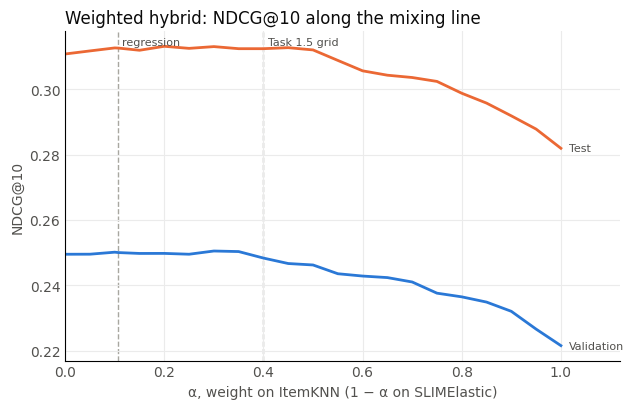

In [6]:
ALPHA_REG = coef["ItemKNN"] / sum(coef.values())
alphas = np.unique(np.r_[np.linspace(0, 1, 21), ALPHA_REG, TASK15_ALPHA])
curve = []
for alpha in alphas:
    row = {"alpha": alpha}
    for split in ("valid", "test"):
        res = evaluate(blend(alpha, 1 - alpha, split), split)["topk"][f"@{K}"]
        row |= {f"{split}_ndcg@{K}": res["ndcg"], f"{split}_mrr@{K}": res["mrr"]}
    curve.append(row)
curve = pd.DataFrame(curve).set_index("alpha")
curve.to_csv(RESULTS_DIR / "alpha_curve.csv")
display(curve.loc[[0.0, ALPHA_REG, TASK15_ALPHA, 1.0]].rename(
    index={0.0: "0 (SLIM only)", ALPHA_REG: f"{ALPHA_REG:.3f} (regression)", TASK15_ALPHA: "0.4 (Task 1.5 grid)",
           1.0: "1 (ItemKNN only)"}).round(4))

fig, ax = plt.subplots(figsize=(6.5, 4.2))
for split, color, label in [("valid", BLUE, "Validation"), ("test", ORANGE, "Test")]:
    c = curve[f"{split}_ndcg@{K}"]
    ax.plot(c.index, c.values, color=color, linewidth=2)
    ax.annotate(label, (1, c.iloc[-1]), xytext=(6, 0), textcoords="offset points", va="center", fontsize=8, color=MUTED)
for alpha, text in [(ALPHA_REG, "regression"), (TASK15_ALPHA, "Task 1.5 grid")]:
    ax.axvline(alpha, color=GRAY, linewidth=1, linestyle="--", zorder=0)
    ax.annotate(text, (alpha, ax.get_ylim()[1]), xytext=(3, -10), textcoords="offset points", fontsize=8, color=MUTED)
ax.set_xlabel("α, weight on ItemKNN (1 − α on SLIMElastic)", color=MUTED)
ax.set_ylabel(f"NDCG@{K}", color=MUTED)
ax.set_title(f"Weighted hybrid: NDCG@{K} along the mixing line", loc="left", color=INK)
ax.set_xlim(0, 1.12)
ax.grid(color="0.92")
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(colors=MUTED, length=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "alpha_curve.png", dpi=200)
plt.show()

## 3. Weighted hybrid: what each component contributes

Both weightings, on the test split: **regression** ($\beta$ from Task 1.3) and **grid** ($\alpha = 0.4$ from Task 1.5).

### 3.1 Share of the final score and origin of the recommended items

For every item in a hybrid top 10:

* **score share**: $\beta_1 S_\text{ItemKNN}(u,i) / (\beta_1 S_\text{ItemKNN}(u,i) + \beta_2 S_\text{SLIM}(u,i))$,
  the part of its final score that ItemKNN provides;
* **origin**: whether the item is also in SLIMElastic's own top 10, ItemKNN's own top 10, both, or neither.
  Items from *ItemKNN only* or *neither* are the ones the blend adds beyond SLIM's list;
* **precision by origin**: the share of those items that are test hits.

In [7]:
HYBRIDS = {"regression": (coef["ItemKNN"], coef["SLIMElastic"]), "grid (α = 0.4)": (TASK15_ALPHA, 1 - TASK15_ALPHA)}
own_top = {c: top_k(S["test"][c], test_users, K) for c in COMPONENTS}
is_hit = lambda u, items: np.isin(items, list(ITEMS["test"][u]))

origin_rows, share_rows = [], []
for hname, (w1, w2) in HYBRIDS.items():
    hybrid_top = top_k(blend(w1, w2, "test"), test_users, K)
    a = S["test"]["ItemKNN"][test_users[:, None], hybrid_top] * w1
    b = S["test"]["SLIMElastic"][test_users[:, None], hybrid_top] * w2
    share_rows.append({"hybrid": hname, "ItemKNN share of score": (a / (a + b)).mean(),
                       "ItemKNN share, rank 1": (a[:, 0] / (a[:, 0] + b[:, 0])).mean()})
    counts = {}
    for row, u in enumerate(test_users):
        in_s, in_i = np.isin(hybrid_top[row], own_top["SLIMElastic"][row]), np.isin(hybrid_top[row], own_top["ItemKNN"][row])
        hits = is_hit(u, hybrid_top[row])
        for name, mask in [("both", in_s & in_i), ("SLIM only", in_s & ~in_i),
                           ("ItemKNN only", ~in_s & in_i), ("neither", ~in_s & ~in_i)]:
            n, h = counts.get(name, (0, 0))
            counts[name] = (n + mask.sum(), h + hits[mask].sum())
    total = len(test_users) * K
    for name, (n, h) in counts.items():
        origin_rows.append({"hybrid": hname, "origin": name, "share of list": n / total,
                            "precision": h / n if n else np.nan, "share of hits": h})
    hits_total = sum(h for _, h in counts.values())
    for r in origin_rows[-4:]:
        r["share of hits"] /= hits_total

shares = pd.DataFrame(share_rows).set_index("hybrid")
origins = pd.DataFrame(origin_rows).set_index(["hybrid", "origin"])
shares.to_csv(RESULTS_DIR / "score_shares.csv")
origins.to_csv(RESULTS_DIR / "list_origin.csv")
display(shares.round(3))
display(origins.round(3))

,ItemKNN share of score,"ItemKNN share, rank 1"
hybrid,,
regression,0.137,0.115
grid (α = 0.4),0.476,0.427


share of list  precision  share of hits
hybrid         origin                                               
regression     both                  0.610      0.243          0.710
               SLIM only             0.351      0.155          0.260
               ItemKNN only          0.029      0.161          0.022
               neither               0.011      0.157          0.008
grid (α = 0.4) both                  0.609      0.243          0.716
               SLIM only             0.247      0.162          0.193
               ItemKNN only          0.124      0.130          0.077
               neither               0.021      0.138          0.014

### 3.2 Ablation: hybrid vs. each component alone

Test accuracy with one component removed, which is the same as the other component alone. Significance:
paired Wilcoxon signed-rank test on per-user NDCG@10, hybrid vs. SLIMElastic alone.

In [8]:
results = {"ItemKNN only": evaluate(blend(1, 0, "test"), "test"),
           "SLIMElastic only": evaluate(blend(0, 1, "test"), "test")}
for hname, (w1, w2) in HYBRIDS.items():
    results[f"hybrid, {hname}"] = evaluate(blend(w1, w2, "test"), "test")

# Task 1.3 reported test NDCG@10 = 0.312579 for the regression hybrid, with its own metric code
assert np.isclose(results["hybrid, regression"]["topk"].loc["ndcg", f"@{K}"], 0.312579, atol=1e-6)

ndcg = {n: r["per_user"][f"ndcg@{K}"] for n, r in results.items()}
ablation = pd.DataFrame({n: {**r["topk"][f"@{K}"][["precision", "recall", "ndcg", "mrr"]].add_suffix(f"@{K}"), "auc": r["auc"]}
                         for n, r in results.items()}).T
ablation[f"ΔNDCG@{K} vs SLIM"] = ablation[f"ndcg@{K}"] - ablation.loc["SLIMElastic only", f"ndcg@{K}"]
ablation["p vs SLIM"] = [np.nan if n == "SLIMElastic only" else wilcoxon(ndcg[n], ndcg["SLIMElastic only"]).pvalue
                         for n in ablation.index]
ablation["users better / worse than SLIM"] = [
    "–" if n == "SLIMElastic only" else f"{(ndcg[n] > ndcg['SLIMElastic only']).sum()} / {(ndcg[n] < ndcg['SLIMElastic only']).sum()}"
    for n in ablation.index]
ablation.to_csv(RESULTS_DIR / "ablation.csv")
display(ablation.style.format({c: "{:.4f}" for c in ablation.columns[:6]} | {"p vs SLIM": "{:.3g}"}, na_rep="–"))

,precision@10,recall@10,ndcg@10,mrr@10,auc,ΔNDCG@10 vs SLIM,p vs SLIM,users better / worse than SLIM
ItemKNN only,0.1830,0.2402,0.2819,0.4827,0.9240,-0.0289,4.82e-09,304 / 436
SLIMElastic only,0.2071,0.2646,0.3108,0.5113,0.9200,0.0000,–,–
"hybrid, regression",0.2089,0.2657,0.3126,0.5125,0.9285,0.0018,0.0468,188 / 146
"hybrid, grid (α = 0.4)",0.2069,0.2651,0.3124,0.5180,0.9288,0.0016,0.2,330 / 281


### 3.3 For which users does ItemKNN help?

Test NDCG@10 per quartile of training-profile size: SLIMElastic alone, and the gain of each hybrid over it.

In [9]:
sizes = pd.Series(profile_size[ndcg["SLIMElastic only"].index], index=ndcg["SLIMElastic only"].index)
quartile = pd.qcut(sizes, 4)
by_size = pd.DataFrame({"users": quartile.value_counts().sort_index(),
                        f"SLIM NDCG@{K}": ndcg["SLIMElastic only"].groupby(quartile, observed=True).mean()})
for hname in HYBRIDS:
    by_size[f"Δ {hname}"] = (ndcg[f"hybrid, {hname}"] - ndcg["SLIMElastic only"]).groupby(quartile, observed=True).mean()
by_size.index = [f"{int(iv.left) + 1}–{int(iv.right)}" for iv in by_size.index]
by_size.index.name = "training profile size"
by_size.to_csv(RESULTS_DIR / "gain_by_profile_size.csv")
display(by_size.round(4))

,users,SLIM NDCG@10,Δ regression,Δ grid (α = 0.4)
training profile size,,,,
16–27,246,0.2469,0.0040,0.0033
28–53,231,0.2551,-0.0011,0.0074
54–120,236,0.2756,0.0008,-0.0044
121–591,230,0.4711,0.0033,0.0002


## 4. Switching hybrid: who gets which component

The switching hybrid has no coefficients. Its "weight" is the share of users routed to each component, and its
one parameter is the threshold $\theta$. Training profiles have at least 16 interactions (the ml-100k
filter, minus the validation and test items), so any $\theta \le 15$, the chosen $\theta = -1$ included, routes **every**
user to SLIMElastic. Popularity contributes nothing to the final lists.

To see *why* the validation search refused to route anyone to Popularity, compare the two components
per profile-size bucket. Switching can only help if Popularity beats SLIM for the users with the smallest profiles.

In [10]:
pop_fn = lambda inter: torch.from_numpy(np.tile(popularity, (len(inter), 1)))
switch = {}
for split, data in [("valid", valid_data), ("test", test_data)]:
    pop_scores, _ = score_matrix(pop_fn, data, N_USERS, N_ITEMS, UID)
    switch[split] = {"Popularity": evaluate(pop_scores, split)["per_user"][f"ndcg@{K}"],
                     "SLIMElastic": evaluate(blend(0, 1, split), split)["per_user"][f"ndcg@{K}"]}

bins = [15, 20, 30, 50, 100, profile_size.max()]
rows = []
for split in ("valid", "test"):
    users = switch[split]["SLIMElastic"].index
    bucket = pd.cut(pd.Series(profile_size[users], index=users), bins)
    for b, idx in bucket.groupby(bucket, observed=True).groups.items():
        p, s = switch[split]["Popularity"][idx], switch[split]["SLIMElastic"][idx]
        rows.append({"split": split, "profile size": f"{int(b.left) + 1}–{int(b.right)}", "users": len(idx),
                     f"Popularity NDCG@{K}": p.mean(), f"SLIM NDCG@{K}": s.mean(),
                     "users where Popularity is better": (p > s).mean()})
switch_table = pd.DataFrame(rows).set_index(["split", "profile size"])

routing = pd.DataFrame({"threshold θ": [-1, 15, 16, 20, 50],
                        "users routed to Popularity": [(profile_size[1:] <= t).mean() for t in [-1, 15, 16, 20, 50]]})
routing.to_csv(RESULTS_DIR / "switch_routing.csv", index=False)
switch_table.to_csv(RESULTS_DIR / "switch_by_profile_size.csv")
display(routing.style.format({"users routed to Popularity": "{:.1%}"}).hide(axis="index"))
display(switch_table.round(3))

threshold θ,users routed to Popularity
-1,0.0%
15,0.0%
16,3.4%
20,12.8%
50,48.6%


users  Popularity NDCG@10  SLIM NDCG@10  \
split profile size                                            
valid 16–20           121               0.095         0.229   
      21–30           152               0.085         0.194   
      31–50           185               0.110         0.219   
      51–100          196               0.096         0.214   
      101–591         289               0.179         0.331   
test  16–20           121               0.110         0.250   
      21–30           152               0.097         0.243   
      31–50           185               0.108         0.265   
      51–100          196               0.125         0.258   
      101–591         289               0.211         0.437   

                    users where Popularity is better  
split profile size                                    
valid 16–20                                    0.099  
      21–30                                    0.132  
      31–50                                    0.162  
      51–100                                   0.153  
      101–591                                  0.156  
test  16–20                                    0.116  
      21–30                                    0.138  
      31–50                                    0.157  
      51–100                                   0.158  
      101–591                                  0.087

## 5. Observations

**Coefficients of the weighted hybrid**

* **SLIMElastic dominates the regression.** $\beta_\text{SLIM} = 0.94$ vs. $\beta_\text{ItemKNN} = 0.11$
  (standardised 0.47 vs. 0.08). Because only the ratio affects the ranking, the hybrid ranks items as
  $0.107\,S_\text{ItemKNN} + 0.893\,S_\text{SLIM}$.
* **ItemKNN brings little information that SLIM does not already have.** The two normalised scores correlate
  at 0.90 on the regression data. Alone, each explains a similar share of the target ($R^2$ 0.26 vs. 0.30).
  Adding ItemKNN to SLIM raises $R^2$ by only 0.001, while adding SLIM to ItemKNN raises it by 0.042.
  Both models learn item–item relations from the same co-occurrences, and SLIM's learned weights subsume
  ItemKNN's fixed cosine similarities.
* **The coefficients are stable but the mix they imply is not unique.** The user-bootstrap 95% CI for
  $\beta_\text{ItemKNN}$ is [0.087, 0.138], and 20 negative-sampling seeds give 0.089–0.120. So, under the linear model,
  ItemKNN's weight is small but not zero. A logistic regression on the same data, however, puts the
  ranking weight at 0.54 instead of 0.11. With two highly correlated inputs, the data barely pin down the
  ratio, and the answer depends on the loss. The coefficients should be read as "SLIM carries most of
  the signal", not as a precise optimal mix.
* **Every mix up to α ≈ 0.5 performs about the same.** Along the mixing line, validation NDCG@10 stays
  between 0.246 and 0.251 for $\alpha \le 0.5$, and test NDCG@10 between 0.311 and 0.313. It falls only
  as ItemKNN takes over. The regression (α = 0.107) and the Task 1.5 grid (α = 0.4) both sit on this
  plateau. The grid preferred 0.4 because of validation MRR@10 differences in the third decimal.

**Contribution to the final recommendations (test)**

* **The regression hybrid is SLIM with small edits.** ItemKNN provides 14% of the final score of the
  recommended items, and 96% of the items are in SLIM's own top 10. On average ItemKNN swaps in 0.4 items
  per list, and those account for 3% of the hits.
* **With α = 0.4, ItemKNN provides half the score (48%) but still changes few items.** 86% of the list is
  still SLIM's own top 10. The 15% it adds hit *less* often (precision 0.13–0.14) than the SLIM-only
  items they replace (0.16), so precision does not improve.
* **Agreement is the strongest signal.** Items in both components' top 10 (61% of every hybrid list) are
  hits 24% of the time, against 13–16% for items only one model ranks highly. Most of the hybrid's value
  is in re-ranking these consensus items.
* **Ablation.** Removing SLIM (ItemKNN alone) costs 0.029 NDCG@10 (p < 1e-8). Removing ItemKNN (SLIM alone)
  costs 0.002, which is barely significant for the regression hybrid (p = 0.047, unadjusted; 188 users better,
  146 worse, 609 unchanged) and not significant for α = 0.4 (p = 0.20). The gain is not concentrated in
  light or heavy users: it changes sign across profile-size quartiles and never exceeds ±0.008.

**Switching hybrid**

* **Popularity contributes nothing.** The chosen θ = −1 routes all 943 users to SLIM, so the hybrid *is*
  SLIMElastic. Every training profile in ml-100k has at least 16 interactions, so there are no cold-start users for
  the switch to help.
* **Popularity never wins on average, even for the smallest profiles.** For users with 16–20 training
  interactions, validation NDCG@10 is 0.095 for Popularity vs. 0.229 for SLIM. Popularity beats SLIM for
  only 10–16% of users in any bucket. Any θ ≥ 16 routes users to the worse component, which is why
  validation MRR@10 falls as soon as θ passes 15.